# Which Of These Factors (Brand, Mileage, Year) Most Linked To Used Car Prices In Saudi Arabia

I built this project because one of my friends was going to buy a used car and i wanted to know what are the most linked factors: year, mileage, engine size, brand and model that increase or decrease prices of used cars in Saudi.

**Data**
The data is from the "Saudi Arabia Used Cars Dataset" on Kaggle, Created by Turki Bintaleb and other collaborators, who which collected the data from the Syarah website. I applied the cleaned English file, Which contains about 8,035 cars and 13 columns. Which is lower than the 8,248 records on the dataset page, and I still dont know what was removed.

**What I did**
The first thing that i realised was that some of the cars had a price of 0 and some had irregular mileage, so i cleared those first, that left me with 5,344 cars. So then I compared the median prices by year, brand and model, and checked how the mileage and engine size related to the price.



In [1]:
import pandas as pd

df = pd.read_csv("UsedCarsSA_Clean_EN.csv")
print(df.shape)
df.head()

(8035, 13)


,Make,Type,Year,Origin,Color,Options,Engine_Size,Fuel_Type,Gear_Type,Mileage,Region,Price,Negotiable
0,Chrysler,C300,2018,Saudi,Black,Full,5.7,Gas,Automatic,103000,Riyadh,114000,False
1,Nissan,Patrol,2016,Saudi,White,Full,4.8,Gas,Automatic,5448,Riyadh,0,True
2,Nissan,Sunny,2019,Saudi,Silver,Standard,1.5,Gas,Automatic,72418,Riyadh,27500,False
3,Hyundai,Elantra,2019,Saudi,Grey,Standard,1.6,Gas,Automatic,114154,Riyadh,43000,False
4,Hyundai,Elantra,2019,Saudi,Silver,Semi Full,2.0,Gas,Automatic,41912,Riyadh,59500,False


In [2]:
df.info()
df.describe()
print((df["Price"] == 0).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8035 entries, 0 to 8034
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Make         8035 non-null   object 
 1   Type         8035 non-null   object 
 2   Year         8035 non-null   int64  
 3   Origin       8035 non-null   object 
 4   Color        8035 non-null   object 
 5   Options      8035 non-null   object 
 6   Engine_Size  8035 non-null   float64
 7   Fuel_Type    8035 non-null   object 
 8   Gear_Type    8035 non-null   object 
 9   Mileage      8035 non-null   int64  
 10  Region       8035 non-null   object 
 11  Price        8035 non-null   int64  
 12  Negotiable   8035 non-null   bool   
dtypes: bool(1), float64(1), int64(3), object(8)
memory usage: 761.3+ KB
2527


In [3]:
print(df.describe())
print(df[df["Price"] == 0]["Negotiable"].value_counts())

              Year  Engine_Size       Mileage         Price
count  8035.000000  8035.000000  8.035000e+03  8.035000e+03
mean   2014.097698     3.287729  1.491488e+05  5.369984e+04
std       5.757228     1.517747  3.474480e+05  7.198472e+04
min    1963.000000     1.000000  1.000000e+02  0.000000e+00
25%    2012.000000     2.000000  3.700000e+04  0.000000e+00
50%    2016.000000     3.000000  1.019600e+05  3.700000e+04
75%    2018.000000     4.400000  1.950000e+05  7.375000e+04
max    2022.000000     9.000000  2.000000e+07  1.150000e+06
Negotiable
True     2526
False       1
Name: count, dtype: int64


**Step 1: Removing fake prices and irregular mileage**

- The output illustrates that the lowest price is 0 and about 25% of the cars were priced at 0, And that 20 million km is the highest mileage, which is impossible to reach with any car.

- I deleted 2,527 cars which were priced at 0. 2,526 of the cars were marked "Negotiable", so I assume that 0 means "no fixed price" and not an actual price.

- I also removed 70 cars with mileage of 500,000 km or more. I picked this cutoff myself and didn't check what happened to other values.

- Result: 8,035 cars turned into 5,438, so 32% of the data was removed.

In [4]:
pd.options.display.float_format = '{:,.0f}'.format

clean = df[df["Price"] > 0].copy()
clean = clean[clean["Mileage"] < 500000]

print(len(df), "->", len(clean))
print(clean[["Year", "Mileage", "Price"]].describe())

8035 -> 5438
       Year  Mileage     Price
count 5,438    5,438     5,438
mean  2,015  121,894    78,963
std       5  101,052    75,256
min   1,963      100         1
25%   2,014   45,000    35,500
50%   2,016  100,000    58,000
75%   2,018  177,815    95,000
max   2,021  498,000 1,150,000


**Step 2: Removing unrealistically low prices**

- The output illustrates that the lowest price is still 1 SAR, Extremely low prices are still in the data after Step 1.

- 94 cars are priced "under 5,000", such as a 2018 Dodge Charger at 2,300 SAR. A recent car cent sell for that little amount, so i believe that these are typos or placeholders.

- I chose the 5,000 SAR cutoff myself and didn't think to check the cars priced just above it.

- I chose to keep the most expensive cars, like the Mercedes G at 1,150,000 SAR, because they look like actual luxury car prices.

- Result: 5,438 cars turned into 5,344.

In [5]:
print((clean["Price"] < 5000).sum())
print(clean[clean["Price"] < 5000][["Make", "Type", "Year", "Price"]].head(10))
print(clean.sort_values("Price", ascending=False)[["Make", "Type", "Year", "Price"]].head(5))

94
         Make      Type  Year  Price
829   Hyundai   Elantra  2020   1221
845   Hyundai    Sonata  2018   1342
852   Hyundai    Sonata  2018   1312
859   Hyundai  Senta fe  2016   1576
1131       MG       RX5  2019   1310
1233    Dodge   Charger  2018   2300
1305      Kia        K5  2021   1630
1482   Nissan    Sentra  2017   1139
1612  Hyundai    Sonata  2018   1670
1661       MG         5  2020    988
          Make      Type  Year    Price
1022  Mercedes         G  2021  1150000
5913   Bentley  Bentayga  2019   850000
3826  Mercedes         G  2019   835000
4038  Mercedes         G  2019   800000
3182   Bentley    Arnage  2020   772500


5344


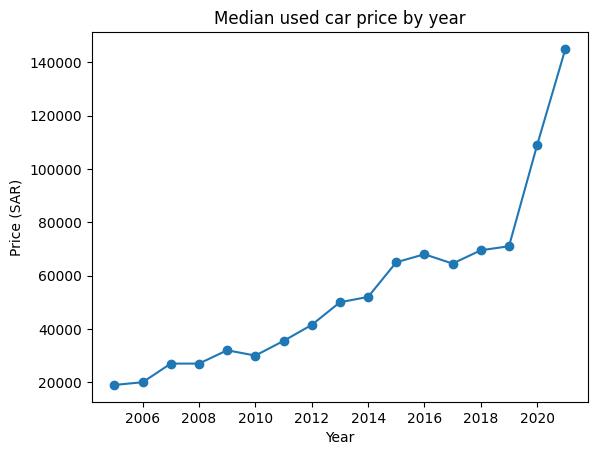

In [6]:
clean = clean[clean["Price"] >= 5000]
print(len(clean))

import matplotlib.pyplot as plt

recent = clean[clean["Year"] >= 2005]
recent.groupby("Year")["Price"].median().plot(kind="line", marker="o")
plt.title("Median used car price by year")
plt.ylabel("Price (SAR)")
plt.show()

**Step 3: Median price by year**

- The chart illustrates the rising of the median price from about 19,000 SAR in 2005 to about 71,000 Sar for 2019 models, then in 2020 it jumps to 109,000 SAR and than in 2021 it turns to 145,000 Sar.

- I left out cars produced prior to 2005, and I used the median so the expensive cars wouldn't affect the line too much.

- The jump after 2019 looks way too big, and I don't fully trust it yet. The newer years have fewer cars (115 for 2021), so I'll test it in the upcoming steps.

In [7]:
recent = clean[clean["Year"] >= 2015]
print(recent.groupby("Year")["Price"].agg(["count", "median"]))

      count  median
Year               
2015    568  65,000
2016    863  68,000
2017    625  64,500
2018    616  69,500
2019    500  71,000
2020    376 109,000
2021    115 145,000


In [8]:
toyota = clean[(clean["Make"] == "Toyota") & (clean["Year"] >= 2015)]
print(toyota.groupby("Year")["Price"].agg(["count", "median"]))

      count  median
Year               
2015    134  57,000
2016    201  65,000
2017    161  66,000
2018    153  68,000
2019     94 112,500
2020     89 120,000
2021     32 168,000


In [9]:
for y in [2018, 2021]:
    print(y)
    print(toyota[toyota["Year"] == y]["Type"].value_counts().head(5))

2018
Type
Corolla    44
Hilux      25
Prado      16
Yaris      16
Rav4       14
Name: count, dtype: int64
2021
Type
Land Cruiser           12
Furniture               5
Land Cruiser Pickup     3
Avalon                  3
Prado                   2
Name: count, dtype: int64


In [10]:
lc = clean[(clean["Make"] == "Toyota") & (clean["Type"] == "Land Cruiser") & (clean["Year"] >= 2015)]
print(lc.groupby("Year")["Price"].agg(["count", "median"]))

      count  median
Year               
2015     19 150,000
2016     12 172,500
2017      7 182,000
2018     10 243,000
2019     25 233,000
2020     16 253,500
2021     12 275,750


**Step 4: Testing the spike with Toyota and the Land Cruiser**

- Toyota illustrates the same major increase: the median goes from 68,000 SAR for 2018 models to 168,000 SAR for 2021 models. So the spike isn't limited to luxury brands.

- The mix of the Toyota models changed. The most common model in 2018 was the Corolla about (44 cars), but in 2021 it was the Land Cruiser (12 out of 32 Toyotas).

- When I took a look at the Land Cruiser on its own, its median rose only about 13%, from 243,000 SAR to 275,750 SAR. This suggests that most of the spike came from the cars which are listed, not from newer cars being worth much more.

- These groups are quite small (7 to 25 Land Cruisers per year), so the numbers are quite rough and not precise.

- Data flaw: 5 out of the 32 Toyotas are from 2021, have a model called "Furniture". It's most possible that it's a translation error about the Fortuner, but I couldn't confirm it, so I left it as it is.


In [11]:
pd.options.display.float_format = '{:,.2f}'.format
print(clean[["Price", "Year", "Mileage", "Engine_Size"]].corr()["Price"])

Price          1.00
Year           0.32
Mileage       -0.28
Engine_Size    0.31
Name: Price, dtype: float64


**Step 5: Correlation with price**

- Year (0.32), mileage (-0.28) and engine size (0.31) are all weakly or moderately linked to the price. Newer cars and bigger engines tend to cost more, and higher mileage tends to go with a lower price, possibly because of wear.

- None of them is close to 1 or -1, so not a single one of these factors explains prices on its own. Correlation also doesn't show cause.

- This test only works with numbers, so brands and models are not included.

In [12]:
brands = clean.groupby("Make")["Price"].agg(["count", "median"])
brands = brands[brands["count"] >= 30].sort_values("median", ascending=False)
print(brands.head(10))
print(brands.tail(5))

            count     median
Make                        
Land Rover     74 242,500.00
Mercedes      254 146,500.00
Lexus         236 142,000.00
Cadillac       35 130,000.00
BMW            92 110,000.00
Audi           37  91,000.00
Genesis        45  88,000.00
Jeep           55  85,000.00
Dodge          81  76,500.00
GMC           239  74,000.00
         count    median
Make                    
Changan     37 44,000.00
Hyundai    686 43,000.00
Kia        256 40,000.00
Nissan     350 37,000.00
Renault     36 26,000.00


In [13]:
y18 = clean[clean["Year"] == 2018]
b = y18.groupby("Make")["Price"].agg(["count", "median"])
b = b[b["count"] >= 15].sort_values("median", ascending=False)
print(b)

           count     median
Make                       
Lexus         24 214,500.00
Mercedes      19 185,000.00
GMC           18 145,750.00
Chevrolet     25  85,000.00
Ford          33  85,000.00
Toyota       153  68,000.00
Kia           28  58,800.00
Mazda         27  55,000.00
Hyundai      146  50,000.00
Nissan        40  30,000.00


**Step 6: Brand within one model year**

- To hold age steady, I compared brands from the 2018 cars only, using brands that had at least 15 cars. That left 10 brands.

- Lexus holds the highest median at 214,500 SAR (24 cars) and Nissan has the lowest median at 30,000 SAR (40 cars).

- The two biggest groups are Toyota (68,000 SAR, 153 cars) and Hyundai (50,000 SAR, 146 cars), being at the lower half of the table.

- Certain groups are small (Mercedes has 19 cars), so these medians are a rough estimate. A brand's median also mixes the cheap and expensive models.

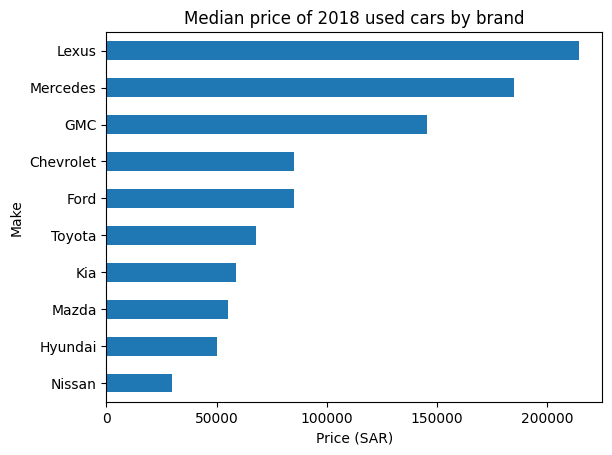

In [14]:
b["median"].plot(kind="barh")
plt.title("Median price of 2018 used cars by brand")
plt.xlabel("Price (SAR)")
plt.gca().invert_yaxis()
plt.show()

**Chart: Median price of 2018 cars by each brand**

- Lexus holds the highest median and Nissan the lowest. Lexus, Mercedes and GMC are all higher than the other brands, and after GMC the bars drop dramatically from 145,750 SAR to 85,000 SAR.

- Every car in this chart is from 2018, so age is the only factor that's fixed. Mileage, engine size and the models each brand sells are not, so the differences could come from any of those and not just from the brand.

- Some bars rest on few cars (Mercedes has 19, GMC has 18), so the heights are not precise, but rough.

**Conclusions and the limitations**

- Main finding: brand and model looked more strongly linked to used car prices than are year (0.32), mileage (-0.28) or engine size (0.31). Among the 2018 cars, the median price ranged 30,000 SAR (Nissan) to 214,500 SAR (Lexus). The 2020-2021 price jump also seems to come mostly from which models were listed, not from the newer cars being worth much more.

- I deleted about a third of the data (8,035 cars turned into 5,344), and I picked the 500,000 km and 5,000 SAR cutoffs myself without testing other values. I also didn't look at regions, fuel types or options.

- These are listing prices and not final sale prices. A lot of the groups are small, and this shows links and not cause.

- Next, I would test that whether the brand gap stayed the same within one region or fuel type.